# Meta-Labeling

Meta-labeling enhances decision making by introducing a secondary model that filters the primary model's predictions; while the primary model predicts a "side" (for example, whether an asset will go up or down), the meta-labeling framework uses the realized outcome to generate a binary indicator that reflects whether the prediction was correct, and then trains a meta-model to estimate the probability that the primary prediction is reliable, thereby enabling one to act only on signals that pass a predefined confidence threshold.


## Procedure

1. **Primary Model Prediction:**  
   Let the primary model be $f$ such that for an input $x_i$, it produces a side $s_i \in \{-1, +1\}$.

2. **Realized Outcome:**  
   For each observation, we have a realized outcome $r_i$ (e.g., the actual return after acting on $s_i$).

3. **Defining the Meta-Label:**  
   The meta-label $\ell_i$ is defined as:
   $$
   \ell_i =
   \begin{cases}
     1, & \text{if } s_i \times r_i > 0, \\
     0, & \text{otherwise}.
   \end{cases}
   $$

4. **Meta-Model Training:**  
   We train a secondary model $g(x_i, s_i)$ to estimate the probability:
   $$
   \hat{p}_i = g(x_i, s_i) \approx \mathbb{P}(\ell_i = 1 \mid x_i, s_i),
   $$
   using a logistic loss function:
   $$
   \mathcal{L}(g) = -\frac{1}{N}\sum_{i=1}^N \left[\ell_i \log g(x_i, s_i) + (1-\ell_i)\log(1 - g(x_i, s_i))\right].
   $$

5. **Decision Rule:**  
   At inference, we decide to act on the primary prediction $s_i$ if $g(x_i, s_i) > \alpha$, where $\alpha \in (0,1)$ is a chosen threshold.


In [1]:
import numpy as np
from sklearn.base import BaseEstimator

def train_meta_model(primary_model: BaseEstimator,
                     secondary_model: BaseEstimator,
                     X: np.ndarray,
                     realized_outcomes: np.ndarray) -> BaseEstimator:
    """
    Trains a secondary (meta) model to predict the correctness of the primary model's predictions.

    Parameters:
        primary_model (BaseEstimator): A trained model with a .predict() method that outputs labels {-1, +1}.
        secondary_model (BaseEstimator): A model with .fit() method that will learn to predict meta-labels.
        X (np.ndarray): Feature matrix of shape (n_samples, n_features).
        realized_outcomes (np.ndarray): Realized outcomes (e.g., returns) corresponding to each sample.

    Returns:
        secondary_model (BaseEstimator): The trained meta-model.
    """
    # Step 1: Use the primary model to predict the "side" for each observation.
    primary_preds = primary_model.predict(X)  # shape: (n_samples,)

    # Step 2: Generate meta-labels.
    # Meta-label is 1 if the predicted side is correct (i.e., s * r > 0), else 0.
    meta_labels = np.where(primary_preds * realized_outcomes > 0, 1, 0)

    # Step 3: Augment the original features with the primary model's predictions.
    # Here, we add the prediction as a new column.
    X_augmented = np.hstack([X, primary_preds.reshape(-1, 1)])

    # Step 4: Train the secondary model on the augmented feature set and meta-labels.
    secondary_model.fit(X_augmented, meta_labels)

    return secondary_model , X_augmented


In [ ]:
# labelling.py is stored in the same folder as this notebook.

In [2]:
from labelling import *

In [4]:
from pathlib import Path
import pickle

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

TICKER = 'AAPL'

DATA_PATH = (
    Path.cwd().parent
    / "Week1 - Numpy and Pandas"
    / "ticker_data_dict.pkl"
)

if DATA_PATH.exists():
    with DATA_PATH.open('rb') as file:
        loaded_dict = pickle.load(file)
    print(f'Loaded data from {DATA_PATH}')

appl = loaded_dict[TICKER]

prices = appl['Close']
volatility = daily_volatility_with_log_returns(prices, 30)
filter_threshold = 1.5
moelcules = cusum_filter_events_dynamic_threshold(np.log(prices), filter_threshold * volatility)
vertical_barriers = vertical_barrier(prices, moelcules, 20)


triple_barrier_events ,tt = meta_events(prices, vertical_barriers.index, [1, 1], volatility, 0, 1, vertical_barriers)
labels = meta_labeling(triple_barrier_events, prices)

Loaded data from g:\My Drive\Teaching\Math 628- Fall 2026\New Github\Math_628_Fall_2026\Week1 - Numpy and Pandas\ticker_data_dict.pkl


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, roc_curve, auc)



combined_data = pd.merge(appl, labels, left_index=True, right_index=True)

data = combined_data.copy()
# Assume apple_new is a pre-loaded DataFrame with your data
selected_columns = ['SMA_20', 'SMA_50', 'EMA_20', 'EMA_50', 'RSI',
                    'MACD', 'MACD_Signal', 'Return', 'Lag_Return_1',
                    'Lag_Return_2', 'Lag_Return_3']

# Filter the dataset to include only rows with label -1 and 1
data = data[data['Label'].isin([-1, 1])]

features = data[selected_columns]
target = data['Label'].values

In [6]:
n = len(data)
train_end = int(0.7 * n)
secondary_end = int(0.9 * n)


X_train = features.iloc[:train_end]
y_train = target[:train_end]

X_secondary = features.iloc[train_end:secondary_end]
y_secondary = target[train_end:secondary_end]

X_test = features.iloc[secondary_end:]
y_test = target[secondary_end:]

In [7]:
primary_model = RandomForestClassifier(n_estimators=1000, class_weight='balanced' , random_state=42)
secondary_model = RandomForestClassifier(n_estimators=100, class_weight='balanced' , random_state=42)
primary_model.fit(X_train, y_train)

secondary_model, X_aug = train_meta_model(primary_model, secondary_model, X_secondary, y_secondary)

In [8]:
X_test

,SMA_20,SMA_50,EMA_20,EMA_50,RSI,MACD,MACD_Signal,Return,Lag_Return_1,Lag_Return_2,Lag_Return_3
Date,,,,,,,,,,,
2023-08-17,183.9937,185.1535,181.1849,181.8337,27.5198,-3.6093,-2.1216,-0.0146,-0.0050,-0.0112,0.0094
2023-08-22,181.5194,184.9344,179.3831,180.9686,37.4712,-3.6480,-2.9106,0.0079,0.0077,0.0028,-0.0146
2023-08-23,180.8699,184.8864,179.3812,180.9056,47.3481,-3.1792,-2.9643,0.0219,0.0079,0.0077,0.0028
2023-08-24,180.0489,184.7540,178.9324,180.6610,39.2188,-3.1502,-3.0015,-0.0262,0.0219,0.0079,0.0077
2023-08-28,178.4174,184.5429,178.7087,180.4315,47.3009,-2.5734,-2.9021,0.0088,0.0126,-0.0262,0.0219
...,...,...,...,...,...,...,...,...,...,...,...
2025-07-21,207.7972,204.4328,208.1348,206.5524,61.7126,2.2987,2.1221,0.0062,0.0055,-0.0007,0.0050
2025-07-30,211.3996,205.1580,210.2707,208.0223,48.6244,1.9073,2.3100,-0.0105,-0.0130,0.0008,0.0006
2025-08-01,210.5985,205.0443,209.2444,207.7662,35.4615,0.6520,1.8399,-0.0250,-0.0071,-0.0105,-0.0130


In [9]:
def compute_pl_for_stratgy(data, features , primary_model , secondary_model , threshold = 0.55):
  label = primary_model.predict(features)
  features['Primary_Prediction'] = label
  prob = secondary_model.predict_proba(features)[:, 1]
  new_data = data.loc[features.index]
  new_data['label'] = label
  new_data['prob'] = prob
  new_data = new_data[new_data['prob'] > threshold]
  invest_length = (new_data['End Time'] - new_data.index).dt.days.astype(int)
  returns =  new_data['Return of Label'] * new_data['label'] * new_data['prob']

  return returns

In [10]:
meta_labeling_result = compute_pl_for_stratgy(data , X_test , primary_model , secondary_model)

c:\Users\aghapour\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(


In [11]:
meta_labeling_result

Date
2023-08-22   -0.0125
2023-08-23    0.0152
2023-08-30    0.0159
2023-09-07    0.0119
2023-09-13   -0.0121
               ...  
2025-07-03    0.0099
2025-07-14   -0.0128
2025-07-30    0.0204
2025-08-06   -0.0216
2025-08-07   -0.0250
Length: 87, dtype: float64

<Axes: xlabel='Date'>

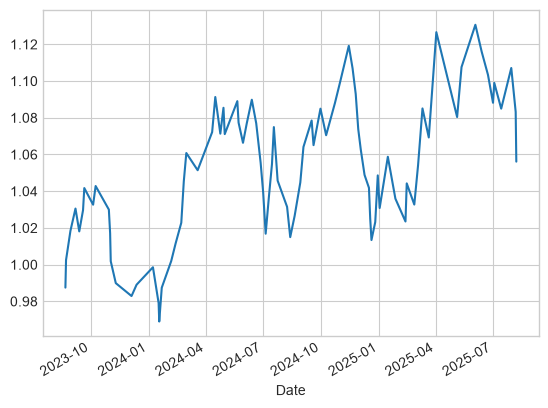

In [12]:
returns = (meta_labeling_result +1).cumprod()
returns.plot()

# Mixture of Guassian betsizing
## 1. Concurrency Variable

Let $\{c_t\}_{t \in \mathcal{T}}$ be a univariate random variable capturing the “concurrency” at time $t$. In many financial contexts, $c_t$ measures the net number of overlapping signals or events at time $t$. For example:

- $c_t > 0$ indicates a net positive concurrency (more long/positive events overlapping than negative ones).
- $c_t < 0$ indicates a net negative concurrency.

We wish to convert $c_t$ into a bet size $m_t \in [0,1]$ that scales our position or leverage according to how “extreme” $c_t$ is relative to its distribution.

---

## 2. Gaussian Mixture Model (GMM)

We model $c_t$ as coming from a univariate mixture of $K$ Gaussians. That is, the probability density function (PDF) of $c_t$ is given by

$$
f(c) \;=\; \sum_{i=1}^K \pi_i \,\mathcal{N}\!\bigl(c \mid \mu_i,\, \sigma_i^2\bigr),
$$

where:

1. $\pi_i > 0$ are *mixture weights* (with $\sum_{i=1}^K \pi_i = 1$).
2. $\mu_i \in \mathbb{R}$ are the *component means*.
3. $\sigma_i^2 > 0$ are the *component variances*.
4. $\mathcal{N}(x \mid \mu,\sigma^2)$ is the standard Gaussian PDF with mean $\mu$ and variance $\sigma^2$.

### 2.1. Mixture CDF

The *cumulative distribution function* (CDF) $F(c)$ of this mixture is

$$
F(c) \;=\; \sum_{i=1}^K \pi_i \,\Phi\!\Bigl(\tfrac{c - \mu_i}{\sigma_i}\Bigr),
$$

where $\Phi$ is the standard normal CDF:

$$
\Phi(z) \;=\; \int_{-\infty}^{z} \frac{1}{\sqrt{2\pi}} e^{-\frac{u^2}{2}}\,du.
$$

Thus, $F(c)$ gives the probability that the concurrency value is $\le c$.

---

## 3. Piecewise Bet Size Definition

We define a special point $F_0 := F(0)$, i.e., the mixture CDF evaluated at $0$. The bet size $m_t$ at time $t$ depends on the sign of $c_t$:

$$
m_t \;=\;
\begin{cases}
\dfrac{F[c_t] \;-\; F_0}{1 \;-\; F_0}, & \text{if } c_t \ge 0,\\[1.0em]
\dfrac{F[c_t] \;-\; F_0}{F_0}, & \text{if } c_t < 0.
\end{cases}
$$

### 3.1. Interpretation

1. **Case $c_t \ge 0$:**  
   The numerator $F[c_t] - F_0$ measures how far $c_t$ is above 0 in terms of the mixture’s distribution. Dividing by $(1 - F_0)$ “normalizes” that excess so that $m_t$ lies in $[0,1]$.  
   - If $c_t = 0$, then $m_t = 0$.  
   - If $c_t$ is very large, $F[c_t] \approx 1$, hence $m_t \approx 1$.

2. **Case $c_t < 0$:**  
   The numerator is the same, $F[c_t] - F_0$, but now we normalize by $F_0$. Because $F[c_t] < F_0$ when $c_t < 0$, the ratio remains within $[-1,0)$ if taken literally. However, by definition, we interpret that ratio in a way that also yields a value in $[0,1]$ (or $[-1,1]$ in some contexts).  
   - If $c_t$ is very negative, $F[c_t] \approx 0$, so $m_t \approx (0 - F_0)/F_0 = -1$. Depending on conventions, we might map that to a 0–1 scale or allow negative bet sizes if short positions are permitted.



## 4. Summary of the Procedure

1. **Fit a GMM:**  
   Given a sample $\{c_1,\dots,c_n\}$, estimate $\{\pi_i,\mu_i,\sigma_i^2\}$ by maximum likelihood (e.g., the EM algorithm) for a univariate mixture of $K$ Gaussians.

2. **Compute $F(c)$:**  
   For each concurrency $c$, compute the CDF:

   $$
   F(c) \;=\; \sum_{i=1}^K \pi_i \,\Phi\!\Bigl(\tfrac{c - \mu_i}{\sigma_i}\Bigr).
   $$

3. **Identify $F_0$:**  
   Evaluate $F_0 = F(0)$.

4. **Map $c_t$ to $m_t$:**  
   For each concurrency value $c_t$, define

   $$
   m_t =
   \begin{cases}
     \dfrac{F[c_t] - F_0}{1 - F_0}, & \text{if } c_t \ge 0,\\[0.75em]
     \dfrac{F[c_t] - F_0}{F_0}, & \text{if } c_t < 0.
   \end{cases}
   $$

The result is a bet size $m_t \in [0,1]$ that grows larger as $c_t$ becomes more extreme in either the positive or negative direction.


In [13]:
import pandas as pd
import numpy as np

def compute_concurrency(events: pd.DataFrame,
                        end_time_col: str = 'end_time',
                        compute_uniqueness: bool = True
                       ) -> pd.DataFrame:
    """
    Compute the concurrency (number of overlapping events) for each row in `events`.
    Optionally compute the uniqueness weight = 1 / concurrency.

    Parameters
    ----------
    events : pd.DataFrame
        DataFrame of events where:
          - The index is the start time of each event.
          - `end_time_col` indicates the end time of each event.
    end_time_col : str
        Column name for the end time in `events`.
    compute_uniqueness : bool
        If True, also compute the uniqueness weight 1/concurrency.

    Returns
    -------
    events_concurrency : pd.DataFrame
        A copy of the input events DataFrame with two new columns:
          - 'concurrency': the concurrency count C_i
          - 'uniqueness': (optionally) 1 / concurrency
    """
    # Ensure the DataFrame is sorted by index (start time)
    events = events.copy()
    events.sort_index(inplace=True)

    # Prepare columns for concurrency and uniqueness
    concurrency_list = []

    start_times = events.index
    end_times = events[end_time_col]

    # Convert index (start times) and end times to arrays for faster access
    start_times_positive = events[events['Label'] > 0 ].index
    end_times_positive = events[events['Label'] > 0 ][end_time_col]

    start_times_negative = events[events['Label'] < 0 ].index
    end_times_negative = events[events['Label'] < 0 ][end_time_col]

    # Naive O(N^2) approach: for each event i, count how many j overlap
    for i in range(len(events)):
        start_i = start_times[i]
        end_i = end_times.iloc[i]


        overlapping_positive = ((start_times_positive <= start_i) & (end_times_positive >  start_i))
        overlapping_negative = ((start_times_negative <= start_i) & (end_times_negative >  start_i))

        concurrency_count = overlapping_positive.sum() - overlapping_negative.sum()
        concurrency_list.append(concurrency_count)

    events['concurrency'] = concurrency_list


    return events



In [14]:
labels

,End Time,Return of Label,Label
event_time,,,
2005-12-29,2006-01-03,0.0462,1
2006-01-03,2006-01-06,0.0207,1
2006-01-10,2006-01-11,0.0376,1
2006-01-11,2006-01-19,-0.0579,-1
2006-01-18,2006-01-19,-0.0418,-1
...,...,...,...
2025-07-21,2025-07-30,-0.0161,-1
2025-07-30,2025-08-01,-0.0319,-1
2025-08-01,2025-08-06,0.0537,1


In [15]:
concurrent = compute_concurrency(labels[labels['Label'].isin([-1, 1])] , 'End Time')

In [16]:
concurrent

,End Time,Return of Label,Label,concurrency
event_time,,,,
2005-12-29,2006-01-03,0.0462,1,1
2006-01-03,2006-01-06,0.0207,1,1
2006-01-10,2006-01-11,0.0376,1,1
2006-01-11,2006-01-19,-0.0579,-1,-1
2006-01-18,2006-01-19,-0.0418,-1,-2
...,...,...,...,...
2025-07-21,2025-07-30,-0.0161,-1,-1
2025-07-30,2025-08-01,-0.0319,-1,-1
2025-08-01,2025-08-06,0.0537,1,1


In [17]:
from sklearn.mixture import GaussianMixture


concurrency_values = concurrent['concurrency'][:secondary_end].values.reshape(-1, 1)

# Choose number of components, for example 2
n_components = 2
gmm = GaussianMixture(n_components=n_components, random_state=42)
gmm.fit(concurrency_values)

,"n_components n_components: int, default=1The number of mixture components.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to the method chosen to initialize theparameters (see `init_params`).In addition, it controls the generation of random samples from thefitted distribution (see the method `sample`).Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"covariance_type covariance_type: {'full', 'tied', 'diag', 'spherical'}, default='full'String describing the type of covariance parameters to use.Must be one of:- 'full': each component has its own general covariance matrix.- 'tied': all components share the same general covariance matrix.- 'diag': each component has its own diagonal covariance matrix.- 'spherical': each component has its own single variance.For an example of using `covariance_type`, refer to:ref:`sphx_glr_auto_examples_mixture_plot_gmm_selection.py`.",'full'
,"tol tol: float, default=1e-3The convergence threshold. EM iterations will stop when thelower bound average gain is below this threshold.",0.001
,"reg_covar reg_covar: float, default=1e-6Non-negative regularization added to the diagonal of covariance.Allows to assure that the covariance matrices are all positive.",1e-06
,"max_iter max_iter: int, default=100The number of EM iterations to perform.",100
,"n_init n_init: int, default=1The number of initializations to perform. The best results are kept.",1
,"init_params init_params: {'kmeans', 'k-means++', 'random', 'random_from_data'}, default='kmeans'The method used to initialize the weights, the means and theprecisions.String must be one of:- 'kmeans' : responsibilities are initialized using kmeans.- 'k-means++' : use the k-means++ method to initialize.- 'random' : responsibilities are initialized randomly.- 'random_from_data' : initial means are randomly selected data points... versionchanged:: v1.1 `init_params` now accepts 'random_from_data' and 'k-means++' as initialization methods.",'kmeans'
,"weights_init weights_init: array-like of shape (n_components, ), default=NoneThe user-provided initial weights.If it is None, weights are initialized using the `init_params` method.",None
,"means_init means_init: array-like of shape (n_components, n_features), default=NoneThe user-provided initial means,If it is None, means are initialized using the `init_params` method.",None
,"precisions_init precisions_init: array-like, default=NoneThe user-provided initial precisions (inverse of the covariancematrices).If it is None, precisions are initialized using the 'init_params'method.The shape depends on 'covariance_type':: (n_components,) if 'spherical', (n_features, n_features) if 'tied', (n_components, n_features) if 'diag', (n_components, n_features, n_features) if 'full'",None


In [18]:
concurrent['concurrency'][secondary_end : ]

event_time
2023-08-17    1
2023-08-22    1
2023-08-23   -1
2023-08-24    1
2023-08-28    1
             ..
2025-07-21   -1
2025-07-30   -1
2025-08-01    1
2025-08-06    1
2025-08-07    1
Name: concurrency, Length: 132, dtype: int64

In [19]:
import numpy as np
from scipy.stats import norm

def gmm_cdf_single(gmm, x: float) -> float:
    """
    Compute the CDF of a univariate Gaussian Mixture Model at a single value x.

    Parameters:
      gmm: A fitted GaussianMixture instance from scikit-learn.
      x: A scalar at which to evaluate the CDF.

    Returns:
      The CDF evaluated at x.
    """
    cdf = 0.0
    for weight, mean, cov in zip(gmm.weights_, gmm.means_, gmm.covariances_):
        # Extract scalar mean and standard deviation.
        mu = mean[0] if isinstance(mean, np.ndarray) else mean
        sigma = np.sqrt(cov[0][0]) if cov.ndim > 1 else np.sqrt(cov)
        cdf += weight * norm.cdf(x, loc=mu, scale=sigma)
    return cdf

def gmm_cdf_array(gmm: GaussianMixture, x_array: np.ndarray) -> np.ndarray:
    """
    Compute the CDF of a univariate Gaussian Mixture Model for each value in x_array (vectorized).
    """
    # Ensure x_array is 1D
    x_array = x_array.ravel()
    cdf_vals = np.zeros_like(x_array, dtype=float)
    for weight, mean, cov in zip(gmm.weights_, gmm.means_, gmm.covariances_):
        mu = mean[0] if mean.ndim else mean
        sigma = np.sqrt(cov[0][0]) if cov.ndim > 1 else np.sqrt(cov)
        cdf_vals += weight * norm.cdf(x_array, loc=mu, scale=sigma)
    return cdf_vals

In [20]:
def compute_m_column(events, gmm, concurrency_col='concurrency', m_col='m'):


    # Copy to avoid modifying original
    events_out = events.copy()

    # 1) Compute F(0)
    F0 = gmm_cdf_single(gmm, 0.0)

    # 2) Compute concurrency array and its GMM CDF
    c_values = events_out[concurrency_col].values
    F_c = gmm_cdf_array(gmm, c_values)  # This gives F[c_t] for each row

    # 3) Apply piecewise definition:
    #    m_t = (F[c_t] - F0) / (1 - F0) if c_t >= 0
    #          (F[c_t] - F0) / F0      if c_t < 0
    m_values = np.where(
        c_values >= 0,
        (F_c - F0) / (1.0 - F0),
        (F_c - F0) / F0
    )

    # Store the result
    events_out[m_col] = m_values

    return events_out


In [21]:
gussian_output = compute_m_column(concurrent[secondary_end: ] , gmm)

In [22]:
gussian_output

,End Time,Return of Label,Label,concurrency,m
event_time,,,,,
2023-08-17,2023-08-22,0.0186,1,1,0.4390
2023-08-22,2023-08-23,0.0219,1,1,0.4390
2023-08-23,2023-08-24,-0.0262,-1,-1,-0.4175
2023-08-24,2023-08-28,0.0216,1,1,0.4390
2023-08-28,2023-08-29,0.0218,1,1,0.4390
...,...,...,...,...,...
2025-07-21,2025-07-30,-0.0161,-1,-1,-0.4175
2025-07-30,2025-08-01,-0.0319,-1,-1,-0.4175
2025-08-01,2025-08-06,0.0537,1,1,0.4390


In [37]:
returns = gussian_output['Return of Label'] * np.abs(gussian_output['m'])

In [38]:
returns

event_time
2023-08-17    0.0081
2023-08-22    0.0096
2023-08-23   -0.0109
2023-08-24    0.0095
2023-08-28    0.0096
               ...  
2025-07-21   -0.0067
2025-07-30   -0.0133
2025-08-01    0.0236
2025-08-06    0.0140
2025-08-07    0.0186
Length: 132, dtype: float64

# Z-statistics for BetSizing

We have a binary label $x \in \{-1,+1\}$ and a predicted probability $p = \Pr(x=+1)$. We test $H_0: p=0.5$ by computing the *z*-score:

$$
z = \frac{2p - 1}{2 \,\sqrt{p(1-p)}},
$$

which measures how many “standard deviations” $p$ is above/below 0.5. We then convert $z$ into a bet size $m \in [-1,1]$ via

$$
m = 2\,\Phi(z) - 1,
$$

where $\Phi$ is the standard normal CDF. As $p$ moves away from 0.5, $z$ grows in magnitude, and $m$ approaches $\pm1$. Hence $m>0$ indicates a long bet on $x=+1$, $m<0$ indicates a short bet on $x=-1$, and $|m|$ reflects confidence.


In [26]:
def z_stat_bet_size(p_array: np.ndarray) -> np.ndarray:

    p_array = np.clip(p_array, 1e-9, 1 - 1e-9)

    # Compute z-score for each probability
    z_vals = (2 * p_array - 1) / (2 * np.sqrt(p_array * (1 - p_array)))

    # Convert z to bet sizes: m = 2*Phi(z) - 1
    m_vals = 2 * norm.cdf(z_vals) - 1
    return m_vals


In [30]:
def compute_pl_for_stratgy(data, features , model , threshold = 0.55):
  label = model.predict(features)
  prob =  model.predict_proba(features)[:, 1]
  new_data = data.loc[features.index]
  new_data['m'] = z_stat_bet_size(prob)

  returns =  new_data['Return of Label']  * new_data['m']

  return returns

In [31]:

combined_data = pd.merge(appl, labels, left_index=True, right_index=True)
data = combined_data.copy()
# Assume apple_new is a pre-loaded DataFrame with your data
selected_columns = ['SMA_20', 'SMA_50', 'EMA_20', 'EMA_50', 'RSI',
                    'MACD', 'MACD_Signal', 'Return', 'Lag_Return_1',
                    'Lag_Return_2', 'Lag_Return_3']

# Filter the dataset to include only rows with label -1 and 1
data = data[data['Label'].isin([-1, 1])]

features = data[selected_columns]
target = data['Label'].values

X_train = features.iloc[:secondary_end]
y_train = target[:secondary_end]

model = RandomForestClassifier(n_estimators=500, class_weight='balanced' , random_state=42)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",500
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.

In [35]:
X_test = features.iloc[secondary_end:]

z_stat_returns = compute_pl_for_stratgy(data , X_test , model)

<Axes: xlabel='Date'>

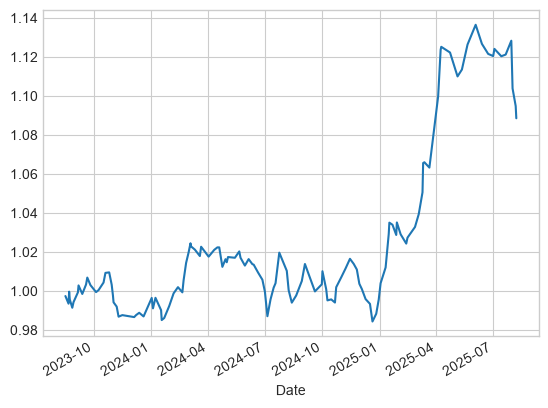

In [36]:
returns = (z_stat_returns +1).cumprod()
returns.plot()